# Global and surface Elo ratings

Calculate one global Elo and independent Hard, Clay, and Grass Elo ratings for every player, then visualize the leading ratings and compare Roger Federer, Rafael Nadal, and Novak Djokovic. Matches sharing a date are evaluated from the same start-of-day rating state, so same-day ordering cannot leak outcomes into pre-match Elo features.

Final parameters remain: initial Elo = 1500, Elo scale = 400, global base K = 32, and surface base K values of 32 (Hard), 40 (Clay), and 52 (Grass). Tournament multipliers are 1.00 (Grand Slam), 1.05 (Masters 1000), 0.95 (ATP500), and 0.90 (ATP250); Masters Cup uses 1.00. Only completed matches are rated, and the only export is the Elo-enriched match CSV under `research/data/output`.

In [1]:
from collections import defaultdict
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

WORKING_DIR = Path.cwd().resolve()
RESEARCH_DIR = WORKING_DIR if WORKING_DIR.name == "research" else WORKING_DIR / "research"
if not RESEARCH_DIR.is_dir():
    raise FileNotFoundError(
        "Run this notebook from the project root or the research directory."
    )

DATA_PATH = RESEARCH_DIR / "data" / "output" / "matches_2015_onwards.csv"

matches = pd.read_csv(DATA_PATH, parse_dates=["Date"], low_memory=False)
matches = matches.sort_values("Date", kind="stable").reset_index(drop=True)

print(f"Loaded {len(matches):,} matches from {DATA_PATH.resolve()}")
print(f"Date range: {matches['Date'].min():%Y-%m-%d} to {matches['Date'].max():%Y-%m-%d}")
matches.head()

Loaded 29,455 matches from /Users/nick/Desktop/tennis live/research/data/output/matches_2015_onwards.csv
Date range: 2015-01-05 to 2026-08-14


,ATP,Location,Tournament,Date,Series,Court,Surface,Round,Best of,Winner,...,Lsets,Comment,B365W,B365L,PSW,PSL,year,source_file,WPts,LPts
0,1,Brisbane,Brisbane International,2015-01-05,ATP250,Outdoor,Hard,1st Round,3.0,Duckworth J.,...,0.0,Completed,4.5,1.18,4.67,1.23,2015,2015.xlsx,430.0,1730.0
1,1,Brisbane,Brisbane International,2015-01-05,ATP250,Outdoor,Hard,1st Round,3.0,Kokkinakis T.,...,0.0,Completed,2.62,1.44,2.67,1.53,2015,2015.xlsx,341.0,1365.0
2,1,Brisbane,Brisbane International,2015-01-05,ATP250,Outdoor,Hard,1st Round,3.0,Chardy J.,...,0.0,Completed,1.28,3.50,1.34,3.50,2015,2015.xlsx,1195.0,691.0
3,1,Brisbane,Brisbane International,2015-01-05,ATP250,Outdoor,Hard,1st Round,3.0,Tomic B.,...,0.0,Completed,1.57,2.25,1.65,2.37,2015,2015.xlsx,797.0,1090.0
4,2,Chennai,Chennai Open,2015-01-05,ATP250,Outdoor,Hard,1st Round,3.0,Muller G.,...,1.0,Completed,1.66,2.10,1.81,2.10,2015,2015.xlsx,855.0,470.0


In [2]:
INITIAL_ELO = 1500.0
ELO_SCALE = 400.0
BASE_K = 32.0
TOURNAMENT_MULTIPLIERS = {
    "Grand Slam": 1.00,
    "Masters 1000": 1.05,
    "ATP500": 0.95,
    "ATP250": 0.90,
}
DEFAULT_TOURNAMENT_MULTIPLIER = 1.00  # Masters Cup


def expected_score(rating_a: float, rating_b: float) -> float:
    """Return player A's expected score against player B."""
    return 1.0 / (1.0 + 10.0 ** ((rating_b - rating_a) / ELO_SCALE))


required = ["Date", "Series", "Winner", "Loser"]
valid_match = matches["Comment"].eq("Completed") & matches[required].notna().all(axis=1)
elo_matches = matches.loc[valid_match].sort_values("Date", kind="stable").reset_index(drop=True)

ratings = defaultdict(lambda: INITIAL_ELO)
elo_rows = []
rating_history = []
match_number = 0

for match_date, day_matches in elo_matches.groupby("Date", sort=True):
    day_deltas = defaultdict(float)
    day_players = set()

    # Every pre-match value comes from the start-of-day state.
    for match in day_matches.itertuples(index=False):
        match_number += 1
        winner = match.Winner
        loser = match.Loser
        tier_multiplier = TOURNAMENT_MULTIPLIERS.get(
            match.Series,
            DEFAULT_TOURNAMENT_MULTIPLIER,
        )
        effective_k = BASE_K * tier_multiplier

        winner_elo_pre = ratings[winner]
        loser_elo_pre = ratings[loser]
        winner_probability = float(
            np.clip(
                expected_score(winner_elo_pre, loser_elo_pre),
                1e-15,
                1.0 - 1e-15,
            )
        )
        rating_change = effective_k * (1.0 - winner_probability)

        # Row-level post values show this match's zero-sum update from its pre values.
        winner_elo_post = winner_elo_pre + rating_change
        loser_elo_post = loser_elo_pre - rating_change
        day_deltas[winner] += rating_change
        day_deltas[loser] -= rating_change
        day_players.update((winner, loser))

        elo_rows.append(
            {
                "TierMultiplier": tier_multiplier,
                "EffectiveK": effective_k,
                "WinnerEloPre": winner_elo_pre,
                "LoserEloPre": loser_elo_pre,
                "WinnerWinProbability": winner_probability,
                "WinnerEloPost": winner_elo_post,
                "LoserEloPost": loser_elo_post,
                "MatchLogLoss": -np.log(winner_probability),
            }
        )

    # Apply all match updates only after every row on the date has its pre values.
    for player, rating_delta in day_deltas.items():
        ratings[player] += rating_delta

    for player in sorted(day_players):
        rating_history.append(
            {
                "MatchNumber": match_number,
                "Date": match_date,
                "Player": player,
                "Elo": ratings[player],
            }
        )

result_columns = ["Date", "Series", "Surface", "Winner", "Loser"]
elo_results = pd.concat(
    [elo_matches[result_columns], pd.DataFrame(elo_rows)],
    axis=1,
)
elo_history = pd.DataFrame(rating_history)
model_log_loss = elo_results["MatchLogLoss"].mean()

global_numeric_columns = [
    "WinnerEloPre",
    "LoserEloPre",
    "WinnerWinProbability",
    "WinnerEloPost",
    "LoserEloPost",
    "MatchLogLoss",
]
assert np.isfinite(elo_results[global_numeric_columns].to_numpy(dtype=float)).all()
assert elo_results["WinnerWinProbability"].between(0.0, 1.0, inclusive="neither").all()
assert (elo_results["WinnerEloPost"] > elo_results["WinnerEloPre"]).all()
assert (elo_results["LoserEloPost"] < elo_results["LoserEloPre"]).all()
assert np.allclose(
    elo_results["WinnerEloPost"] - elo_results["WinnerEloPre"],
    -(elo_results["LoserEloPost"] - elo_results["LoserEloPre"]),
)
assert np.isclose(sum(ratings.values()), INITIAL_ELO * len(ratings))

global_pre_by_player = pd.concat(
    [
        elo_results[["Date", "Winner", "WinnerEloPre"]].rename(
            columns={"Winner": "Player", "WinnerEloPre": "EloPre"}
        ),
        elo_results[["Date", "Loser", "LoserEloPre"]].rename(
            columns={"Loser": "Player", "LoserEloPre": "EloPre"}
        ),
    ],
    ignore_index=True,
)
assert (
    global_pre_by_player.groupby(["Date", "Player"], sort=False)["EloPre"]
    .nunique(dropna=False)
    .le(1)
    .all()
), "A player's global pre-match Elo changed within a date."

print(f"Calculated {len(elo_results):,} matches with base K = {BASE_K:g}")
print(f"Mean log loss: {model_log_loss:.4f}")
print("Global Elo validation passed, including start-of-day batching.")
display(elo_results.head())

Calculated 28,425 matches with base K = 32
Mean log loss: 0.6236
Global Elo validation passed, including start-of-day batching.


,Date,Series,Surface,Winner,Loser,TierMultiplier,EffectiveK,WinnerEloPre,LoserEloPre,WinnerWinProbability,WinnerEloPost,LoserEloPost,MatchLogLoss
0,2015-01-05,ATP250,Hard,Duckworth J.,Simon G.,0.9,28.8,1500.0,1500.0,0.5,1514.4,1485.6,0.693147
1,2015-01-05,ATP250,Hard,Kokkinakis T.,Benneteau J.,0.9,28.8,1500.0,1500.0,0.5,1514.4,1485.6,0.693147
2,2015-01-05,ATP250,Hard,Chardy J.,Golubev A.,0.9,28.8,1500.0,1500.0,0.5,1514.4,1485.6,0.693147
3,2015-01-05,ATP250,Hard,Tomic B.,Querrey S.,0.9,28.8,1500.0,1500.0,0.5,1514.4,1485.6,0.693147
4,2015-01-05,ATP250,Hard,Muller G.,Roger-Vasselin E.,0.9,28.8,1500.0,1500.0,0.5,1514.4,1485.6,0.693147


In [3]:
# Independent Elo ratings for Hard, Clay, and Grass.
SURFACE_BASE_K = {
    "Hard": 32.0,
    "Clay": 40.0,
    "Grass": 52.0,
}
surface_matches = elo_matches.dropna(subset=["Surface"]).reset_index(drop=True)
surface_ratings = defaultdict(lambda: INITIAL_ELO)
surface_elo_rows = []
surface_rating_history = []
surface_match_number = 0

for match_date, day_matches in surface_matches.groupby("Date", sort=True):
    day_deltas = defaultdict(float)
    day_player_keys = set()

    # Every surface pre-match value comes from the start-of-day state.
    for match in day_matches.itertuples(index=False):
        surface_match_number += 1
        surface = match.Surface
        winner = match.Winner
        loser = match.Loser
        winner_key = (surface, winner)
        loser_key = (surface, loser)
        tier_multiplier = TOURNAMENT_MULTIPLIERS.get(
            match.Series,
            DEFAULT_TOURNAMENT_MULTIPLIER,
        )
        surface_base_k = SURFACE_BASE_K[surface]
        effective_k = surface_base_k * tier_multiplier

        winner_elo_pre = surface_ratings[winner_key]
        loser_elo_pre = surface_ratings[loser_key]
        winner_probability = float(
            np.clip(
                expected_score(winner_elo_pre, loser_elo_pre),
                1e-15,
                1.0 - 1e-15,
            )
        )
        rating_change = effective_k * (1.0 - winner_probability)

        # Row-level post values show this match's zero-sum update from its pre values.
        winner_elo_post = winner_elo_pre + rating_change
        loser_elo_post = loser_elo_pre - rating_change
        day_deltas[winner_key] += rating_change
        day_deltas[loser_key] -= rating_change
        day_player_keys.update((winner_key, loser_key))

        surface_elo_rows.append(
            {
                "SurfaceBaseK": surface_base_k,
                "WinnerSurfaceEloPre": winner_elo_pre,
                "LoserSurfaceEloPre": loser_elo_pre,
                "WinnerSurfaceWinProbability": winner_probability,
                "WinnerSurfaceEloPost": winner_elo_post,
                "LoserSurfaceEloPost": loser_elo_post,
                "SurfaceMatchLogLoss": -np.log(winner_probability),
            }
        )

    # Apply all match updates only after every row on the date has its pre values.
    for player_key, rating_delta in day_deltas.items():
        surface_ratings[player_key] += rating_delta

    for surface, player in sorted(day_player_keys):
        surface_rating_history.append(
            {
                "MatchNumber": surface_match_number,
                "Date": match_date,
                "Surface": surface,
                "Player": player,
                "Elo": surface_ratings[(surface, player)],
            }
        )

surface_elo_results = pd.concat(
    [
        surface_matches[["Date", "Series", "Surface", "Winner", "Loser"]],
        pd.DataFrame(surface_elo_rows),
    ],
    axis=1,
)
surface_elo_history = pd.DataFrame(surface_rating_history)
surface_final_ratings = pd.DataFrame(
    [
        {"Surface": surface, "Player": player, "Elo": rating}
        for (surface, player), rating in surface_ratings.items()
    ]
).sort_values(["Surface", "Elo"], ascending=[True, False])

surface_numeric_columns = [
    "WinnerSurfaceEloPre",
    "LoserSurfaceEloPre",
    "WinnerSurfaceWinProbability",
    "WinnerSurfaceEloPost",
    "LoserSurfaceEloPost",
    "SurfaceMatchLogLoss",
]
assert np.isfinite(surface_elo_results[surface_numeric_columns].to_numpy(dtype=float)).all()
assert surface_elo_results["WinnerSurfaceWinProbability"].between(
    0.0,
    1.0,
    inclusive="neither",
).all()
assert (
    surface_elo_results["WinnerSurfaceEloPost"]
    > surface_elo_results["WinnerSurfaceEloPre"]
).all()
assert (
    surface_elo_results["LoserSurfaceEloPost"]
    < surface_elo_results["LoserSurfaceEloPre"]
).all()
assert np.allclose(
    surface_elo_results["WinnerSurfaceEloPost"]
    - surface_elo_results["WinnerSurfaceEloPre"],
    -(
        surface_elo_results["LoserSurfaceEloPost"]
        - surface_elo_results["LoserSurfaceEloPre"]
    ),
)
assert np.isclose(
    sum(surface_ratings.values()),
    INITIAL_ELO * len(surface_ratings),
)

surface_pre_by_player = pd.concat(
    [
        surface_elo_results[
            ["Date", "Surface", "Winner", "WinnerSurfaceEloPre"]
        ].rename(
            columns={"Winner": "Player", "WinnerSurfaceEloPre": "EloPre"}
        ),
        surface_elo_results[
            ["Date", "Surface", "Loser", "LoserSurfaceEloPre"]
        ].rename(
            columns={"Loser": "Player", "LoserSurfaceEloPre": "EloPre"}
        ),
    ],
    ignore_index=True,
)
assert (
    surface_pre_by_player.groupby(
        ["Date", "Surface", "Player"],
        sort=False,
    )["EloPre"]
    .nunique(dropna=False)
    .le(1)
    .all()
), "A player's surface pre-match Elo changed within a date."

surface_log_loss = (
    surface_elo_results.groupby("Surface", as_index=False)
    .agg(
        BaseK=("SurfaceBaseK", "first"),
        Matches=("SurfaceMatchLogLoss", "size"),
        SurfaceEloLogLoss=("SurfaceMatchLogLoss", "mean"),
    )
    .merge(
        elo_results.groupby("Surface", as_index=False)
        .agg(GlobalEloLogLoss=("MatchLogLoss", "mean")),
        on="Surface",
        how="left",
    )
)
surface_log_loss["ImprovementVsGlobal"] = (
    surface_log_loss["GlobalEloLogLoss"] - surface_log_loss["SurfaceEloLogLoss"]
)

print(f"Overall surface-specific Elo log loss: {surface_elo_results['SurfaceMatchLogLoss'].mean():.4f}")
print("Surface Elo validation passed, including start-of-day batching.")
display(surface_log_loss.sort_values("Surface"))
display(surface_final_ratings.groupby("Surface", group_keys=False).head(10))

Overall surface-specific Elo log loss: 0.6316
Surface Elo validation passed, including start-of-day batching.


,Surface,BaseK,Matches,SurfaceEloLogLoss,GlobalEloLogLoss,ImprovementVsGlobal
0,Clay,40.0,8921,0.641591,0.638166,-0.003425
1,Grass,52.0,3370,0.647543,0.613349,-0.034194
2,Hard,32.0,16134,0.622711,0.617615,-0.005096


,Surface,Player,Elo
1096,Clay,Alcaraz C.,2079.779168
1013,Clay,Sinner J.,2043.108624
327,Clay,Zverev A.,1931.627027
216,Clay,Nadal R.,1914.241036
296,Clay,Djokovic N.,1854.376531
775,Clay,Ruud C.,1848.817376
1111,Clay,Musetti L.,1845.746318
1408,Clay,Fils A.,1836.462179
1172,Clay,Rune H.,1815.692297
300,Clay,Federer R.,1775.132237


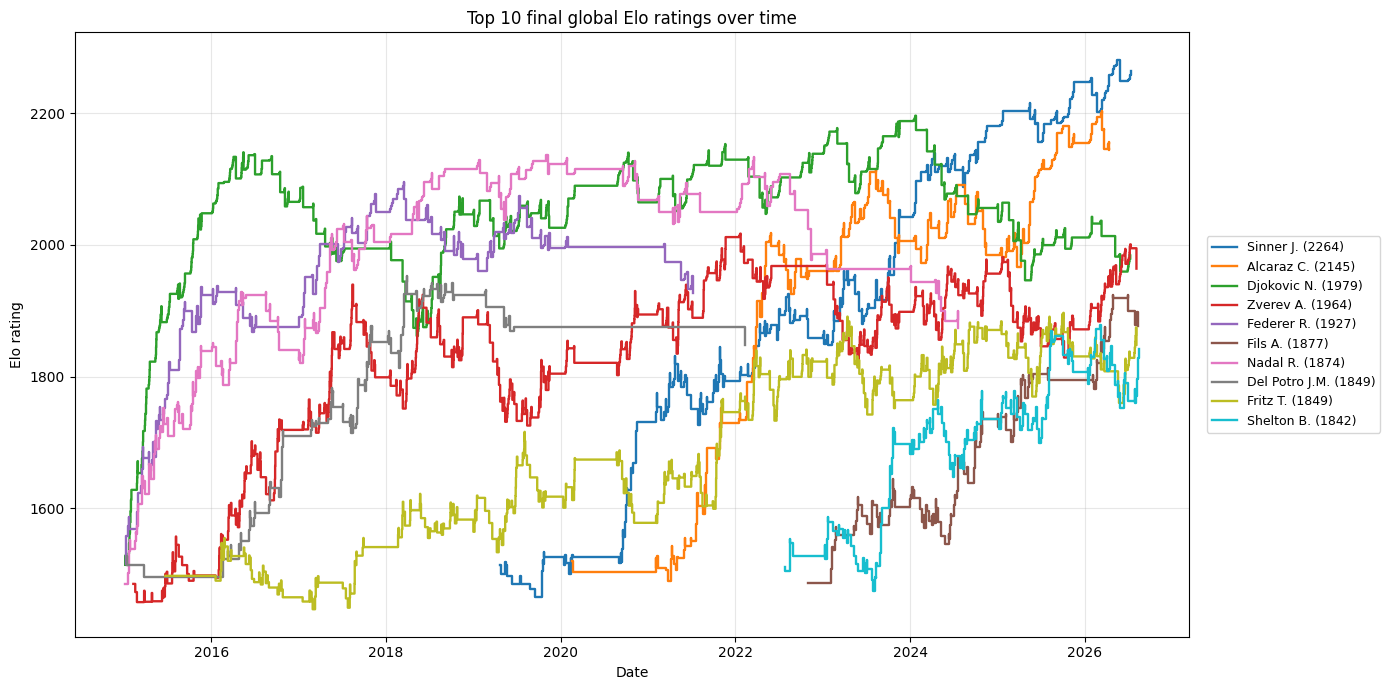

In [4]:
final_ratings = pd.DataFrame(
    [
        {"Player": player, "Elo": rating}
        for player, rating in ratings.items()
    ]
).sort_values("Elo", ascending=False)

top10_ratings = final_ratings.head(10)

fig, ax = plt.subplots(figsize=(14, 7))

for row in top10_ratings.itertuples(index=False):
    player_history = elo_history.loc[
        elo_history["Player"].eq(row.Player)
    ].sort_values("MatchNumber")
    ax.plot(
        player_history["Date"],
        player_history["Elo"],
        linewidth=1.7,
        drawstyle="steps-post",
        label=f"{row.Player} ({row.Elo:.0f})",
    )

ax.set_title("Top 10 final global Elo ratings over time")
ax.set_xlabel("Date")
ax.set_ylabel("Elo rating")
ax.grid(True, alpha=0.3)
ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5), fontsize=9)
ax.xaxis.set_major_locator(mdates.YearLocator(2))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

fig.tight_layout()
plt.show()

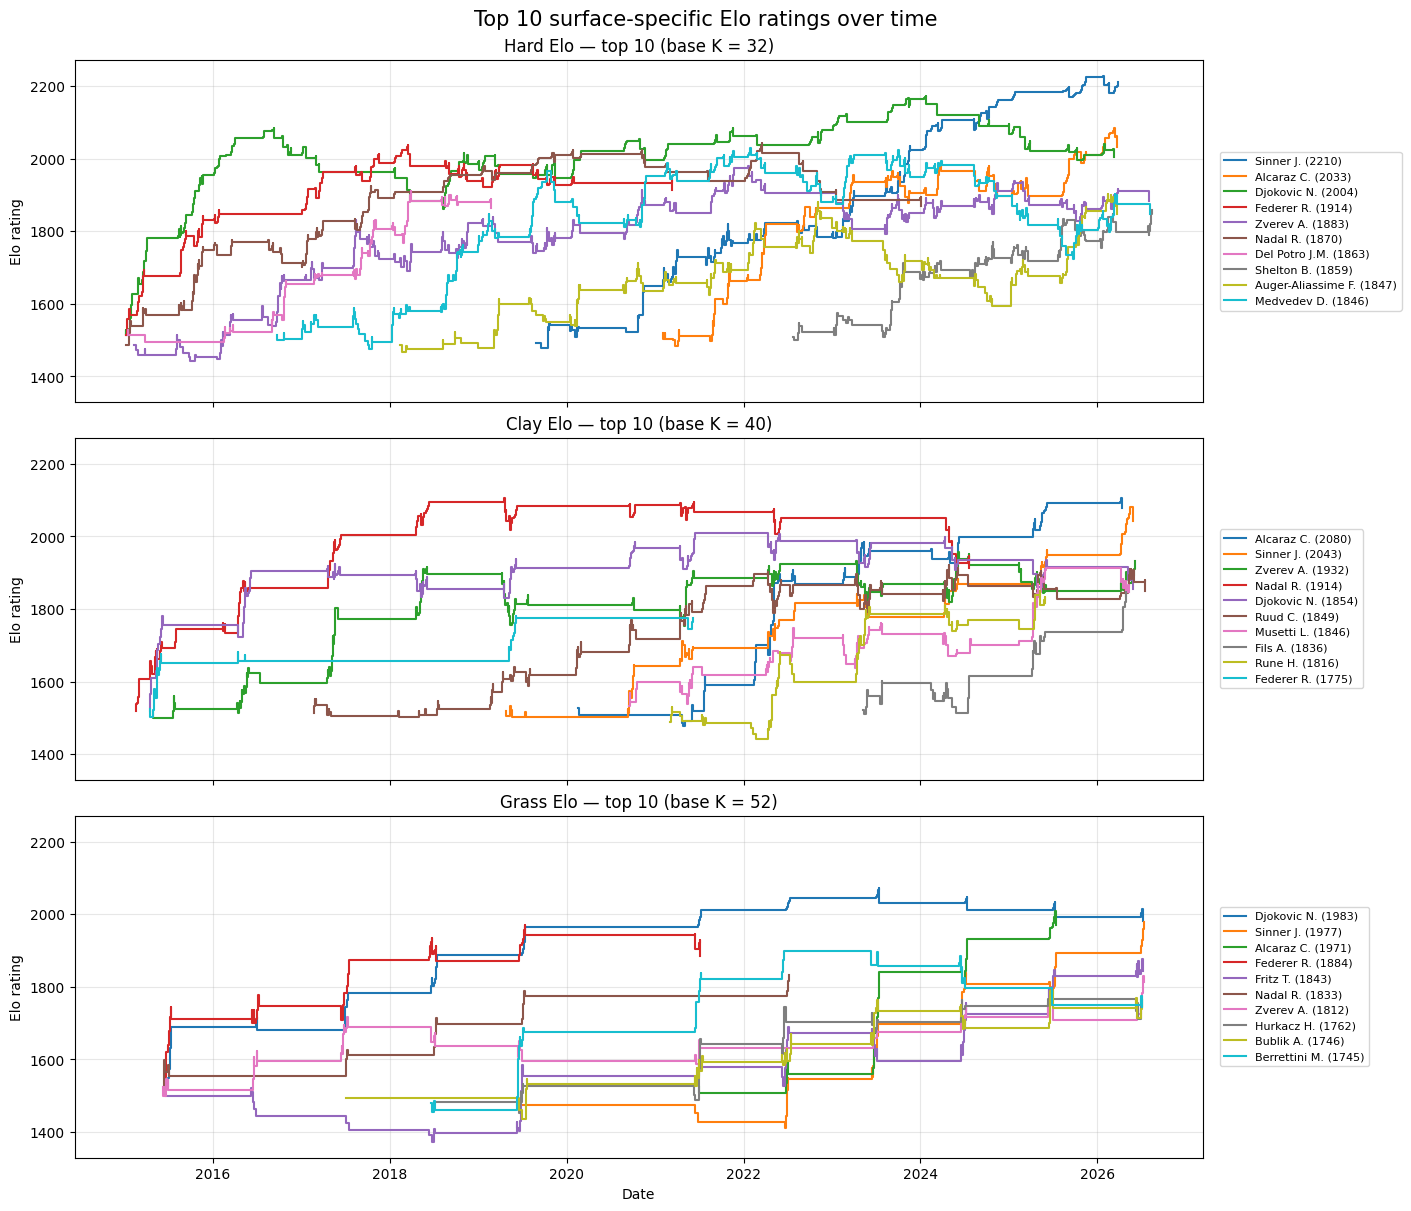

In [5]:
surface_order = ["Hard", "Clay", "Grass"]
fig, axes = plt.subplots(
    3,
    1,
    figsize=(14, 12),
    sharex=True,
    sharey=True,
    constrained_layout=True,
)

for ax, surface in zip(axes, surface_order):
    surface_top10 = surface_final_ratings.loc[
        surface_final_ratings["Surface"].eq(surface)
    ].head(10)

    for row in surface_top10.itertuples(index=False):
        player_history = surface_elo_history.loc[
            surface_elo_history["Surface"].eq(surface)
            & surface_elo_history["Player"].eq(row.Player)
        ].sort_values("MatchNumber")
        ax.plot(
            player_history["Date"],
            player_history["Elo"],
            linewidth=1.5,
            drawstyle="steps-post",
            label=f"{row.Player} ({row.Elo:.0f})",
        )

    ax.set_title(f"{surface} Elo — top 10 (base K = {SURFACE_BASE_K[surface]:g})")
    ax.set_ylabel("Elo rating")
    ax.grid(True, alpha=0.3)
    ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5), fontsize=8)
    ax.xaxis.set_major_locator(mdates.YearLocator(2))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

axes[-1].set_xlabel("Date")
fig.suptitle("Top 10 surface-specific Elo ratings over time", fontsize=15)
plt.show()

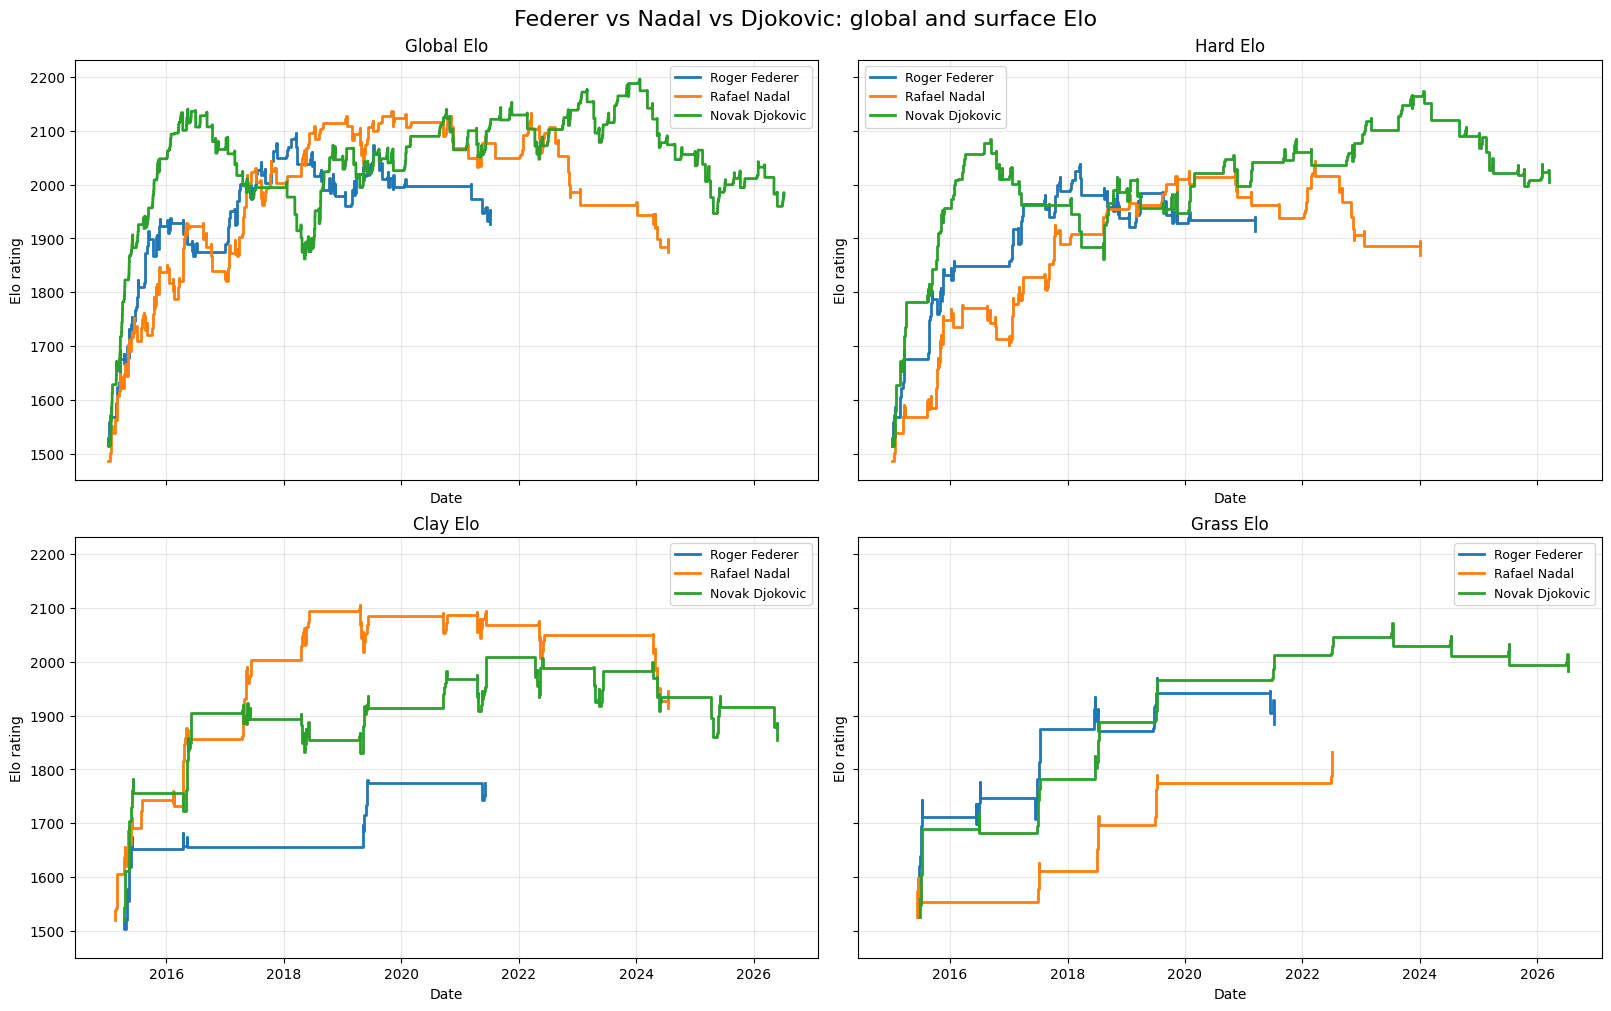

In [6]:
BIG_THREE = {
    "Federer R.": "Roger Federer",
    "Nadal R.": "Rafael Nadal",
    "Djokovic N.": "Novak Djokovic",
}
BIG_THREE_COLORS = {
    "Federer R.": "tab:blue",
    "Nadal R.": "tab:orange",
    "Djokovic N.": "tab:green",
}

fig, axes = plt.subplots(
    2,
    2,
    figsize=(16, 10),
    sharex=True,
    sharey=True,
    constrained_layout=True,
)
panels = [
    ("Global Elo", None),
    ("Hard Elo", "Hard"),
    ("Clay Elo", "Clay"),
    ("Grass Elo", "Grass"),
]

for ax, (title, surface) in zip(axes.ravel(), panels):
    for player, label in BIG_THREE.items():
        if surface is None:
            player_history = elo_history.loc[
                elo_history["Player"].eq(player)
            ].sort_values("MatchNumber")
        else:
            player_history = surface_elo_history.loc[
                surface_elo_history["Surface"].eq(surface)
                & surface_elo_history["Player"].eq(player)
            ].sort_values("MatchNumber")

        ax.plot(
            player_history["Date"],
            player_history["Elo"],
            linewidth=2,
            drawstyle="steps-post",
            color=BIG_THREE_COLORS[player],
            label=label,
        )

    ax.set_title(title)
    ax.set_xlabel("Date")
    ax.set_ylabel("Elo rating")
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=9)
    ax.xaxis.set_major_locator(mdates.YearLocator(2))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

fig.suptitle("Federer vs Nadal vs Djokovic: global and surface Elo", fontsize=16)
plt.show()

In [7]:
# Add global and surface Elo features to every original match row.
enriched_matches = matches.copy()
completed_indices = matches.index[valid_match]
surface_valid_match = valid_match & matches["Surface"].notna()
surface_indices = matches.index[surface_valid_match]

assert len(completed_indices) == len(elo_results)
assert len(surface_indices) == len(surface_elo_results)

global_column_map = {
    "TournamentMultiplier": "TierMultiplier",
    "GlobalEffectiveK": "EffectiveK",
    "WinnerGlobalEloPre": "WinnerEloPre",
    "LoserGlobalEloPre": "LoserEloPre",
    "WinnerGlobalWinProbability": "WinnerWinProbability",
    "WinnerGlobalEloPost": "WinnerEloPost",
    "LoserGlobalEloPost": "LoserEloPost",
    "GlobalMatchLogLoss": "MatchLogLoss",
}

for output_column, result_column in global_column_map.items():
    enriched_matches[output_column] = np.nan
    enriched_matches.loc[completed_indices, output_column] = elo_results[
        result_column
    ].to_numpy()

enriched_matches["GlobalBaseK"] = np.nan
enriched_matches.loc[completed_indices, "GlobalBaseK"] = BASE_K

surface_column_map = {
    "SurfaceBaseK": "SurfaceBaseK",
    "WinnerSurfaceEloPre": "WinnerSurfaceEloPre",
    "LoserSurfaceEloPre": "LoserSurfaceEloPre",
    "WinnerSurfaceWinProbability": "WinnerSurfaceWinProbability",
    "WinnerSurfaceEloPost": "WinnerSurfaceEloPost",
    "LoserSurfaceEloPost": "LoserSurfaceEloPost",
    "SurfaceMatchLogLoss": "SurfaceMatchLogLoss",
}

for output_column, result_column in surface_column_map.items():
    enriched_matches[output_column] = np.nan
    enriched_matches.loc[surface_indices, output_column] = surface_elo_results[
        result_column
    ].to_numpy()

enriched_matches["SurfaceEffectiveK"] = (
    enriched_matches["SurfaceBaseK"] * enriched_matches["TournamentMultiplier"]
)

OUTPUT_PATH = RESEARCH_DIR / "data" / "output" / "matches_2015_onwards_with_elo.csv"
assert OUTPUT_PATH.resolve().parent == (RESEARCH_DIR / "data" / "output").resolve()
enriched_matches.to_csv(OUTPUT_PATH, index=False)

print(f"Exported {len(enriched_matches):,} rows × {enriched_matches.shape[1]} columns")
print(f"Saved to {OUTPUT_PATH.resolve()}")
display(
    enriched_matches[
        [
            "Date",
            "Series",
            "Surface",
            "Winner",
            "Loser",
            "WinnerGlobalEloPre",
            "LoserGlobalEloPre",
            "WinnerSurfaceEloPre",
            "LoserSurfaceEloPre",
        ]
    ].head()
)

Exported 29,455 rows × 51 columns
Saved to /Users/nick/Desktop/tennis live/research/data/output/matches_2015_onwards_with_elo.csv


,Date,Series,Surface,Winner,Loser,WinnerGlobalEloPre,LoserGlobalEloPre,WinnerSurfaceEloPre,LoserSurfaceEloPre
0,2015-01-05,ATP250,Hard,Duckworth J.,Simon G.,1500.0,1500.0,1500.0,1500.0
1,2015-01-05,ATP250,Hard,Kokkinakis T.,Benneteau J.,1500.0,1500.0,1500.0,1500.0
2,2015-01-05,ATP250,Hard,Chardy J.,Golubev A.,1500.0,1500.0,1500.0,1500.0
3,2015-01-05,ATP250,Hard,Tomic B.,Querrey S.,1500.0,1500.0,1500.0,1500.0
4,2015-01-05,ATP250,Hard,Muller G.,Roger-Vasselin E.,1500.0,1500.0,1500.0,1500.0


In [8]:
# Research-only boundary
#
# Runtime player snapshots and Elo parameter artifacts are not exported here.
# The Elo-enriched match CSV under research/data/output is this notebook's only write.